In [ ]:
import pandas as pd  #pandas: la manipulation et l’analyse de données
import numpy as np   #numpy: calculs numériques
import matplotlib.pyplot as plt #matplotlib: des graphes
import seaborn as sns    # seaborn: jolis graphiques statistiques
import warnings
warnings.filterwarnings('ignore') #ignore tous les warnings, ne les affiche plus

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder


from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

from sklearn.ensemble import RandomForestClassifier

In [ ]:
#============================================================
#2. CHARGEMENT DES DONNÉES
#============================================================"
df = pd.read_csv("/content/data_trouble_type.csv")

#Dimensions
print(f"Shape: {df.shape}")

#Premières lignes
display(df.head())



Shape: (5000, 23)


,Does he have health probems ?,Does he have social family problems?,Is there a variation between his real qualifications and its results?,Does he have any difficulties?,Does your child avoid activities that require reading to complete?,he ?it fast/slow while reading ?,"When reading aloud, does your child repeat words, change their order, or mix up similar letters (?\ or ?\? or ?\? or p/b or f/v or k/g/jÉ) without notice?",Does he have trouble reading unknown words?,Does he face difficulty understanding what he read?,Does he reflect numbers? {Ex 81 -> 18},...,Does he have a problem copying?,Does it confuse symbols and/or mathematical operations?,Does he have trouble comparing the relative size of integers and/or fractions?,Does he have difficulties with concepts related to time and/or money?,Is it difficult to understand the statement of calculations and solve it?,Is he having difficulties in calculating? {Facing problems in performing arithmetic operations such as addition and subtraction ...},Is he having trouble maintaining attention for more than 15 minutes?,It takes a long time to complete simple tasks?,Does he have a hard time bearing boredom or strenuous tasks?,TypeTrouble
0,No,No,Yeah,In particular article,Repeatedly / always,Average,Rarely / never,Sometimes,Rarely / never,Rarely / never,...,Repeatedly / always,Sometimes,Repeatedly / always,Sometimes,Sometimes,Repeatedly / always,Repeatedly / always,Rarely / never,Repeatedly / always,Type_dyscalculie
1,No,No,No,In particular article,Sometimes,Average,Repeatedly / always,Rarely / never,Sometimes,Sometimes,...,Rarely / never,Sometimes,Repeatedly / always,Repeatedly / always,Rarely / never,Sometimes,Repeatedly / always,Rarely / never,Repeatedly / always,Concentration
2,Yeah,Yeah,Yeah,In particular article,Rarely / never,Average,Sometimes,Repeatedly / always,Repeatedly / always,Rarely / never,...,Rarely / never,Rarely / never,Sometimes,Sometimes,Repeatedly / always,Repeatedly / always,Sometimes,Repeatedly / always,Rarely / never,Type_dyslexie
3,No,No,Yeah,In all materials,Sometimes,Slow,Repeatedly / always,Rarely / never,Sometimes,Sometimes,...,Repeatedly / always,Rarely / never,Sometimes,Repeatedly / always,Sometimes,Sometimes,Repeatedly / always,Repeatedly / always,Sometimes,Concentration
4,Yeah,Yeah,No,In particular article,Repeatedly / always,Average,Repeatedly / always,Repeatedly / always,Rarely / never,Sometimes,...,Rarely / never,Rarely / never,Rarely / never,Rarely / never,Rarely / never,Rarely / never,Rarely / never,Rarely / never,Rarely / never,Type_dyslexie


In [ ]:
# 2. Dictionnaire de renommage (Ordre exact du dataset)
# Nous utilisons des noms courts, sans espaces, idéaux pour les graphiques XAI
column_mapping = {
    'Does he have health probems ?': 'health_problems',
    'Does he have social family problems?': 'social_family_problems',
    'Is there a variation between his real qualifications and its results?': 'gap_results_potential',
    'Does he have any difficulties?': 'difficulty_area',
    'Does your child avoid activities that require reading to complete?': 'avoid_reading',
    'he ?it fast/slow while reading ?': 'reading_speed',
    'When reading aloud, does your child repeat words, change their order, or mix up similar letters (?\\ or ?\\? or ?\\? or p/b or f/v or k/g/jÉ) without notice?': 'letter_confusion',
    'Does he have trouble reading unknown words?': 'reading_unknown_words',
    'Does he face difficulty understanding what he read?': 'reading_comprehension',
    'Does he reflect numbers? {Ex 81 -> 18}': 'number_reversal',
    'Does he have trouble writing numbers clearly and distinctly from letters?': 'number_writing_clarity',
    'Does he make misspellings in his homework?': 'homework_misspelling',
    'Is he having trouble writing on the line and inside the margins?': 'writing_alignment',
    'Does he have a problem copying?': 'copying_difficulty',
    'Does it confuse symbols and/or mathematical operations?': 'math_symbol_confusion',
    'Does he have trouble comparing the relative size of integers and/or fractions?': 'math_size_comparison',
    'Does he have difficulties with concepts related to time and/or money?': 'time_money_concepts',
    'Is it difficult to understand the statement of calculations and solve it?': 'math_statement_understanding',
    'Is he having difficulties in calculating? {Facing problems in performing arithmetic operations such as addition and subtraction ...}': 'calculation_difficulty',
    'Is he having trouble maintaining attention for more than 15 minutes?': 'attention_span_15min',
    'It takes a long time to complete simple tasks?': 'slow_task_completion',
    'Does he have a hard time bearing boredom or strenuous tasks?': 'boredom_tolerance',

}

# Application du renommage
df = df.rename(columns=column_mapping)

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 23 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   health_problems               5000 non-null   object
 1   social_family_problems        5000 non-null   object
 2   gap_results_potential         5000 non-null   object
 3   difficulty_area               5000 non-null   object
 4   avoid_reading                 5000 non-null   object
 5   reading_speed                 5000 non-null   object
 6   letter_confusion              5000 non-null   object
 7   reading_unknown_words         5000 non-null   object
 8   reading_comprehension         5000 non-null   object
 9   number_reversal               5000 non-null   object
 10  number_writing_clarity        5000 non-null   object
 11  homework_misspelling          5000 non-null   object
 12  writing_alignment             5000 non-null   object
 13  copying_difficulty

In [ ]:
print("\n--- Distribution de la cible (TypeTrouble) ---")
print(df['TypeTrouble'].value_counts())


--- Distribution de la cible (TypeTrouble) ---
TypeTrouble
Type_dysgraphie     1456
Concentration       1329
Type_dyslexie       1200
Type_dyscalculie    1015
Name: count, dtype: int64


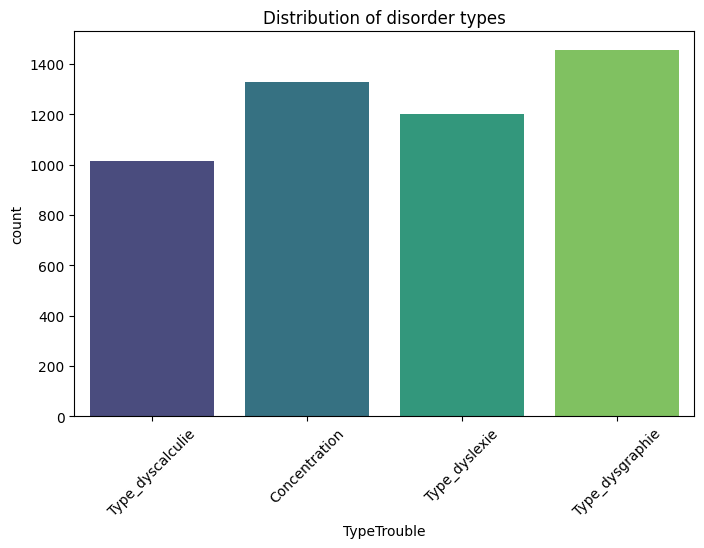

In [ ]:
# Visualisation de la distribution de la variable cible
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='TypeTrouble', palette='viridis')
plt.title('Distribution of disorder types')
plt.xticks(rotation=45)
plt.show()

In [ ]:
print("Valeurs manquantes:\n")
print(df.isnull().sum())

Valeurs manquantes:

health_problems                 0
social_family_problems          0
gap_results_potential           0
difficulty_area                 0
avoid_reading                   0
reading_speed                   0
letter_confusion                0
reading_unknown_words           0
reading_comprehension           0
number_reversal                 0
number_writing_clarity          0
homework_misspelling            0
writing_alignment               0
copying_difficulty              0
math_symbol_confusion           0
math_size_comparison            0
time_money_concepts             0
math_statement_understanding    0
calculation_difficulty          0
attention_span_15min            0
slow_task_completion            0
boredom_tolerance               0
TypeTrouble                     0
dtype: int64


In [ ]:
print("Doublons:", df.duplicated().sum())

Doublons: 0


In [ ]:
for col in df.columns:
    print(f"--- Question :  ---")
    print(df[col].value_counts())
    print("-" * 30)

--- Question :  ---
health_problems
No      2549
Yeah    2451
Name: count, dtype: int64
------------------------------
--- Question :  ---
social_family_problems
Yeah    2520
No      2480
Name: count, dtype: int64
------------------------------
--- Question :  ---
gap_results_potential
No      2527
Yeah    2473
Name: count, dtype: int64
------------------------------
--- Question :  ---
difficulty_area
In all materials         2534
In particular article    2466
Name: count, dtype: int64
------------------------------
--- Question :  ---
avoid_reading
Sometimes              1721
Rarely / never         1667
Repeatedly / always    1612
Name: count, dtype: int64
------------------------------
--- Question :  ---
reading_speed
Average    1709
Slow       1663
Fast       1628
Name: count, dtype: int64
------------------------------
--- Question :  ---
letter_confusion
Rarely / never         1687
Sometimes              1658
Repeatedly / always    1655
Name: count, dtype: int64
----------------

Convertir en scores numeriques

In [ ]:
mapping_scale = {
    "No": 0,
    "Yeah": 1,
    "Rarely / never": 0,
    "Sometimes": 1,
    "Repeatedly / always": 2,
    "Average": 1,
    "Slow": 0,
    "Fast": 2,
    "In particular article": 0,
    "In all materials": 1
}

In [ ]:
df_encoded = df.replace(mapping_scale)
df_encoded.head()

,health_problems,social_family_problems,gap_results_potential,difficulty_area,avoid_reading,reading_speed,letter_confusion,reading_unknown_words,reading_comprehension,number_reversal,...,copying_difficulty,math_symbol_confusion,math_size_comparison,time_money_concepts,math_statement_understanding,calculation_difficulty,attention_span_15min,slow_task_completion,boredom_tolerance,TypeTrouble
0,0,0,1,0,2,1,0,1,0,0,...,2,1,2,1,1,2,2,0,2,Type_dyscalculie
1,0,0,0,0,1,1,2,0,1,1,...,0,1,2,2,0,1,2,0,2,Concentration
2,1,1,1,0,0,1,1,2,2,0,...,0,0,1,1,2,2,1,2,0,Type_dyslexie
3,0,0,1,1,1,0,2,0,1,1,...,2,0,1,2,1,1,2,2,1,Concentration
4,1,1,0,0,2,1,2,2,0,1,...,0,0,0,0,0,0,0,0,0,Type_dyslexie


In [ ]:
# ===============================
# 1. IMPORTS
# ===============================
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# ===============================
# 2. COPIE DU DATASET (sécurité)
# ===============================
df_encoded = df.copy()

# ===============================
# 3. NETTOYAGE (important)
# ===============================
# enlever espaces inutiles
df_encoded = df_encoded.apply(lambda x: x.str.strip() if x.dtype == "object" else x)

# ===============================
# 4. MAPPINGS PAR TYPE
# ===============================

# Oui / Non
yes_no_map = {
    "No": 0,
    "Yeah": 1
}

# Fréquence
freq_map = {
    "Rarely / never": 0,
    "Sometimes": 1,
    "Repeatedly / always": 2
}

# Vitesse
speed_map = {
    "Slow": 0,
    "Average": 1,
    "Fast": 2
}

# Zone de difficulté
difficulty_map = {
    "In particular article": 0,
    "In all materials": 1
}

# ===============================
# 5. APPLICATION DU MAPPING
# ===============================

df_encoded = df_encoded.replace(yes_no_map)
df_encoded = df_encoded.replace(freq_map)
df_encoded = df_encoded.replace(speed_map)
df_encoded = df_encoded.replace(difficulty_map)

# ===============================
# 6. ENCODAGE DE LA TARGET
# ===============================

le = LabelEncoder()
df_encoded["TypeTrouble"] = le.fit_transform(df_encoded["TypeTrouble"])

# ===============================
# 7. SÉPARATION X / y
# ===============================

X = df_encoded.drop("TypeTrouble", axis=1)
y = df_encoded["TypeTrouble"]

# ===============================
# 8. VÉRIFICATIONS
# ===============================

print("Types des colonnes :")
print(df_encoded.dtypes)

print("\nColonnes encore en texte (doit être vide) :")
print(df_encoded.select_dtypes(include='object').columns)

print("\nMapping des classes :")
print(dict(zip(le.classes_, le.transform(le.classes_))))

Types des colonnes :
health_problems                 int64
social_family_problems          int64
gap_results_potential           int64
difficulty_area                 int64
avoid_reading                   int64
reading_speed                   int64
letter_confusion                int64
reading_unknown_words           int64
reading_comprehension           int64
number_reversal                 int64
number_writing_clarity          int64
homework_misspelling            int64
writing_alignment               int64
copying_difficulty              int64
math_symbol_confusion           int64
math_size_comparison            int64
time_money_concepts             int64
math_statement_understanding    int64
calculation_difficulty          int64
attention_span_15min            int64
slow_task_completion            int64
boredom_tolerance               int64
TypeTrouble                     int64
dtype: object

Colonnes encore en texte (doit être vide) :
Index([], dtype='object')

Mapping des classes

In [ ]:
df_encoded.head(10)

,health_problems,social_family_problems,gap_results_potential,difficulty_area,avoid_reading,reading_speed,letter_confusion,reading_unknown_words,reading_comprehension,number_reversal,...,copying_difficulty,math_symbol_confusion,math_size_comparison,time_money_concepts,math_statement_understanding,calculation_difficulty,attention_span_15min,slow_task_completion,boredom_tolerance,TypeTrouble
0,0,0,1,0,2,1,0,1,0,0,...,2,1,2,1,1,2,2,0,2,1
1,0,0,0,0,1,1,2,0,1,1,...,0,1,2,2,0,1,2,0,2,0
2,1,1,1,0,0,1,1,2,2,0,...,0,0,1,1,2,2,1,2,0,3
3,0,0,1,1,1,0,2,0,1,1,...,2,0,1,2,1,1,2,2,1,0
4,1,1,0,0,2,1,2,2,0,1,...,0,0,0,0,0,0,0,0,0,3
5,1,1,0,1,2,2,1,1,1,1,...,2,0,0,1,2,1,2,2,1,0
6,1,0,1,1,2,2,0,1,1,1,...,0,2,1,1,2,0,0,2,1,1
7,1,1,1,0,0,0,1,1,1,1,...,2,2,2,1,2,0,2,1,2,0
8,1,0,1,0,0,2,2,0,1,2,...,0,1,0,2,0,0,1,1,1,2
9,1,1,0,1,0,2,1,0,0,0,...,2,1,0,0,2,0,0,2,1,0


Correlation

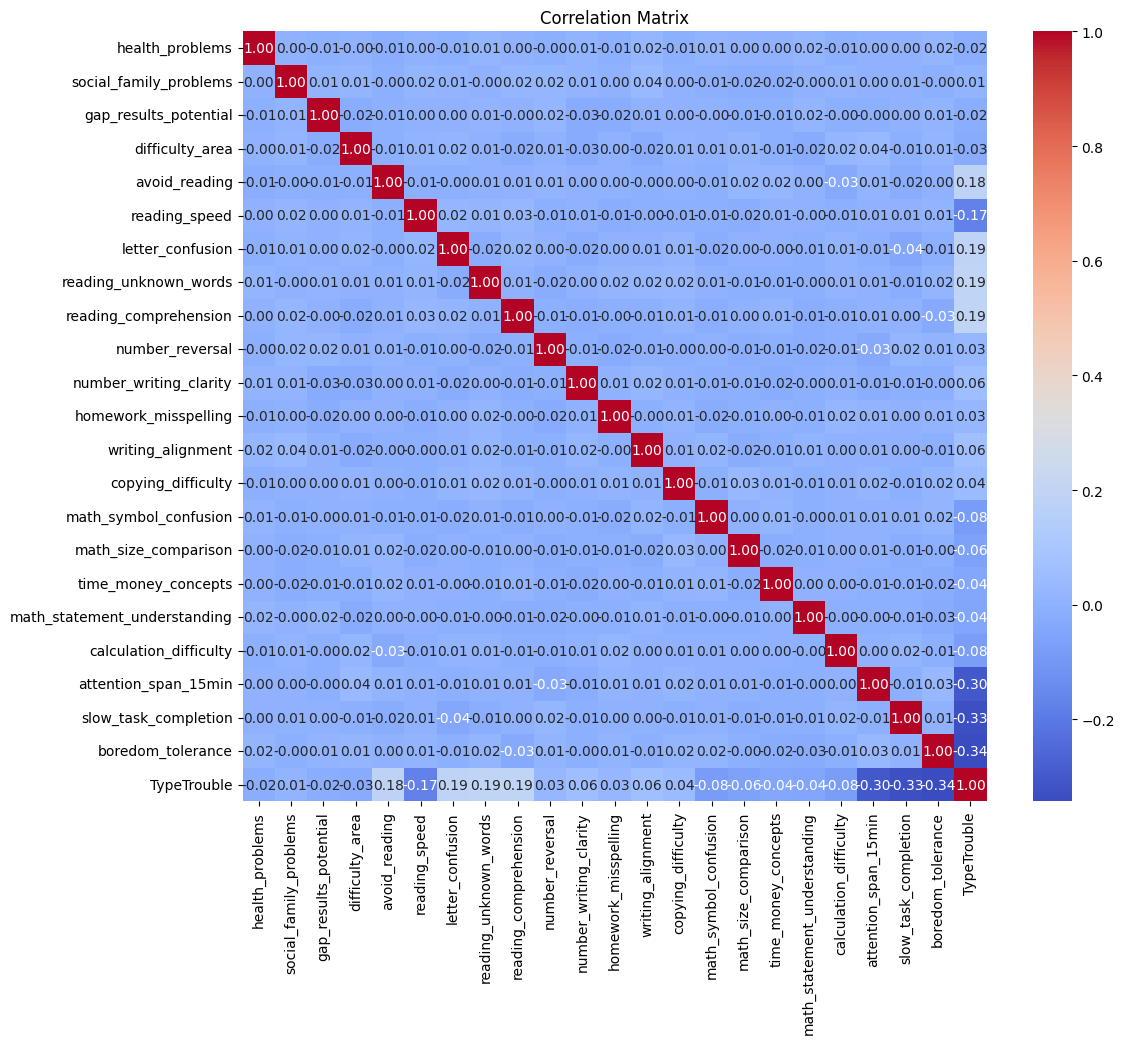

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# matrice de corrélation
corr_matrix = df_encoded.corr()

# affichage
plt.figure(figsize=(12,10))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

In [ ]:
corr_target = df_encoded.corr()["TypeTrouble"].sort_values(ascending=False)

print(corr_target)

TypeTrouble                     1.000000
reading_comprehension           0.194971
reading_unknown_words           0.193835
letter_confusion                0.188222
avoid_reading                   0.184453
writing_alignment               0.063514
number_writing_clarity          0.060910
copying_difficulty              0.043950
number_reversal                 0.026265
homework_misspelling            0.025303
social_family_problems          0.010111
health_problems                -0.016291
gap_results_potential          -0.017043
difficulty_area                -0.026599
time_money_concepts            -0.042423
math_statement_understanding   -0.044091
math_size_comparison           -0.061488
calculation_difficulty         -0.080019
math_symbol_confusion          -0.082937
reading_speed                  -0.174561
attention_span_15min           -0.302514
slow_task_completion           -0.328712
boredom_tolerance              -0.342961
Name: TypeTrouble, dtype: float64


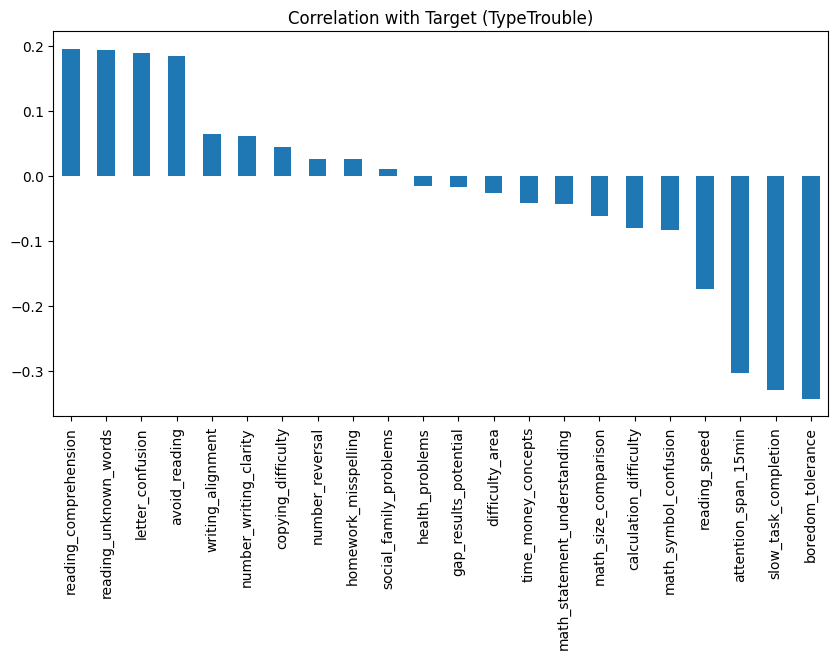

In [ ]:
corr_target.drop("TypeTrouble").plot(kind="bar", figsize=(10,5))
plt.title("Correlation with Target (TypeTrouble)")
plt.show()

In [ ]:
df_corr = df_encoded.copy()

# créer une colonne par maladie
for cls in df_corr["TypeTrouble"].unique():
    df_corr[f"class_{cls}"] = (df_corr["TypeTrouble"] == cls).astype(int)

Corrélation pour chaque maladie Comprendre les caractéristiques de chaque trouble Identifier les symptômes dominants

In [ ]:
# récupérer mapping inverse
class_names = dict(zip(le.transform(le.classes_), le.classes_))

for cls in df_corr["TypeTrouble"].unique():

    print(f"\n===== Classe {cls} : {class_names[cls]} =====")

    corr = df_corr.corr()[f"class_{cls}"].sort_values(ascending=False)

    # enlever colonnes inutiles
    corr = corr.drop([f"class_{cls}", "TypeTrouble"])

    print(corr.head(10))


===== Classe 1 : Type_dyscalculie =====
math_size_comparison            0.242233
calculation_difficulty          0.241971
math_symbol_confusion           0.239840
time_money_concepts             0.238205
math_statement_understanding    0.221785
reading_speed                   0.088935
difficulty_area                 0.018496
health_problems                 0.003429
social_family_problems         -0.011496
gap_results_potential          -0.011953
Name: class_1, dtype: float64

===== Classe 0 : Concentration =====
boredom_tolerance         0.425151
slow_task_completion      0.396271
attention_span_15min      0.380096
reading_speed             0.068253
gap_results_potential     0.029589
difficulty_area           0.017625
health_problems           0.014059
social_family_problems   -0.007077
math_symbol_confusion    -0.042201
number_reversal          -0.046503
Name: class_0, dtype: float64

===== Classe 3 : Type_dyslexie =====
reading_comprehension     0.257929
letter_confusion          0.

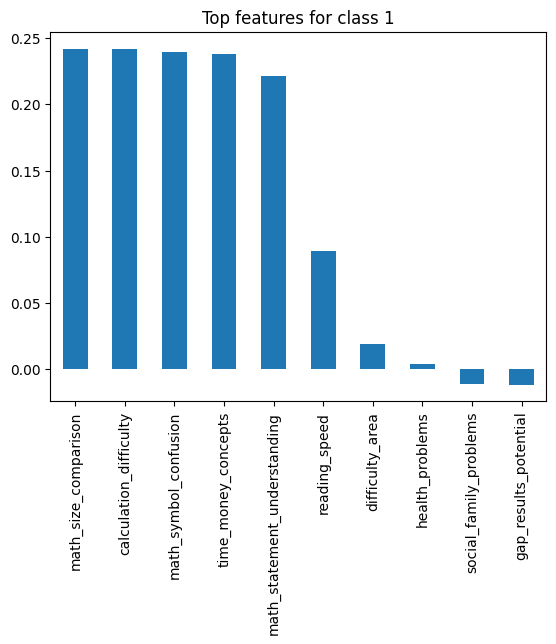

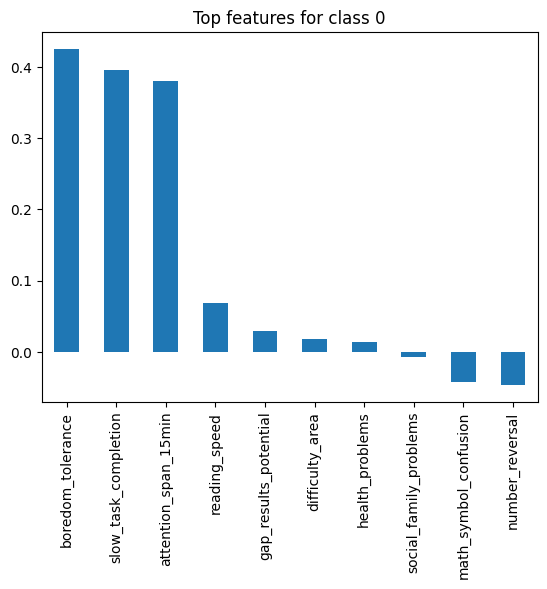

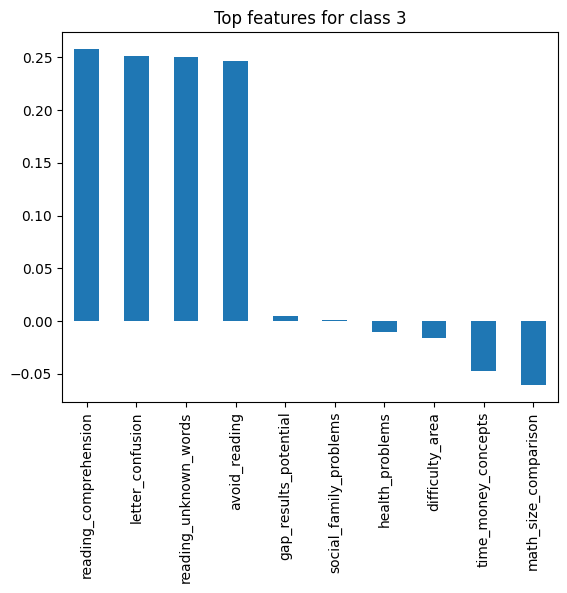

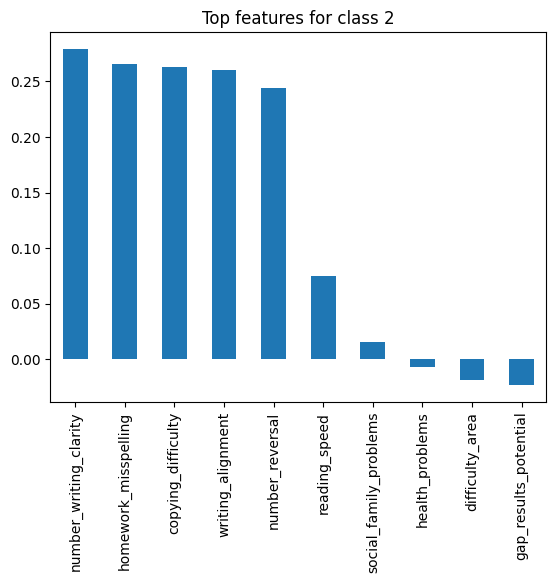

In [ ]:
import matplotlib.pyplot as plt

for cls in df_corr["TypeTrouble"].unique():
    corr = df_corr.corr()[f"class_{cls}"].drop([f"class_{cls}", "TypeTrouble"])

    corr.sort_values(ascending=False).head(10).plot(kind="bar")
    plt.title(f"Top features for class {cls}")
    plt.show()

MODÉLISATION COMPLÈTE (STRUCTURÉE)

SPlIT DATA

In [ ]:
# ===============================
# SPLIT TRAIN / TEST
# ===============================
from sklearn.model_selection import train_test_split

X = df_encoded.drop("TypeTrouble", axis=1)
y = df_encoded["TypeTrouble"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

Train size: (4000, 22)
Test size: (1000, 22)


SCALING (IMPORTANT POUR SVM & NN) Normalisation

In [ ]:
# ===============================
# SCALING
# ===============================
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Modele de base

In [ ]:
# ===============================
# MODELES DE BASE
# ===============================
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

models = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(),
    "Neural Network": MLPClassifier(max_iter=300, random_state=42),
    "XGBoost": XGBClassifier(eval_metric='mlogloss', random_state=42)
}

results_base = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    results_base[name] = acc
    print(f"{name}: {acc:.4f}")

Random Forest: 0.8090
SVM: 0.9380
Neural Network: 0.9960
XGBoost: 0.8960


In [ ]:
# ===============================
# MODELES OPTIMISÉS
# ===============================

# XGBoost (BEST)
best_xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=0.1,
    reg_alpha=0.1,
    reg_lambda=1,
    eval_metric='mlogloss',
    random_state=42
)

best_xgb.fit(X_train, y_train)

# SVM
best_svm = SVC(C=10, gamma=0.01, kernel='rbf')
best_svm.fit(X_train_scaled, y_train)

# Neural Network
best_mlp = MLPClassifier(
    hidden_layer_sizes=(128,64),
    alpha=0.001,
    learning_rate_init=0.001,
    max_iter=500,
    random_state=42
)

best_mlp.fit(X_train_scaled, y_train)

# Random Forest (régularisé)
best_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=4,
    min_samples_split=10,
    random_state=42
)

best_rf.fit(X_train, y_train)
# ===============================
# RESULTATS
# ===============================

# Predictions
pred_xgb = best_xgb.predict(X_test)
pred_svm = best_svm.predict(X_test_scaled)
pred_mlp = best_mlp.predict(X_test_scaled)
pred_rf = best_rf.predict(X_test)

# Accuracy
acc_xgb = accuracy_score(y_test, pred_xgb)
acc_svm = accuracy_score(y_test, pred_svm)
acc_mlp = accuracy_score(y_test, pred_mlp)
acc_rf = accuracy_score(y_test, pred_rf)

# Affichage
print("\n===== RESULTATS DES MODELES OPTIMISÉS =====")

print(f"XGBoost Accuracy : {acc_xgb:.4f}")
print(f"SVM Accuracy : {acc_svm:.4f}")
print(f"Neural Network Accuracy : {acc_mlp:.4f}")
print(f"Random Forest Accuracy : {acc_rf:.4f}")


===== RESULTATS DES MODELES OPTIMISÉS =====
XGBoost Accuracy : 0.9490
SVM Accuracy : 0.9900
Neural Network Accuracy : 0.9930
Random Forest Accuracy : 0.8100


ÉVALUATION + OVERFITTING

In [ ]:
# ===============================
# EVALUATION COMPLETE
# ===============================
from sklearn.model_selection import cross_val_score

def evaluate(model, Xtr, Xte, ytr, yte, name):
    train_acc = model.score(Xtr, ytr)
    test_acc = model.score(Xte, yte)
    cv = cross_val_score(model, Xtr, ytr, cv=5)

    print(f"\n===== {name} =====")
    print("Train:", round(train_acc,4))
    print("Test:", round(test_acc,4))
    print("CV mean:", round(cv.mean(),4))

    if train_acc - test_acc > 0.05:
        print("Overfitting")
    else:
        print("OK")

# evaluation
evaluate(best_rf, X_train, X_test, y_train, y_test, "Random Forest")
evaluate(best_xgb, X_train, X_test, y_train, y_test, "XGBoost")
evaluate(best_svm, X_train_scaled, X_test_scaled, y_train, y_test, "SVM")
evaluate(best_mlp, X_train_scaled, X_test_scaled, y_train, y_test, "Neural Network")


===== Random Forest =====
Train: 0.9828
Test: 0.81
CV mean: 0.8175
Overfitting

===== XGBoost =====
Train: 0.9982
Test: 0.949
CV mean: 0.9462
OK

===== SVM =====
Train: 0.999
Test: 0.99
CV mean: 0.9802
OK

===== Neural Network =====
Train: 1.0
Test: 0.993
CV mean: 0.992
OK


COMPARAISON FINALE

In [ ]:
# ===============================
# COMPARAISON
# ===============================
import pandas as pd

final_results = {
    "Random Forest": best_rf.score(X_test, y_test),
    "XGBoost": best_xgb.score(X_test, y_test),
    "SVM": best_svm.score(X_test_scaled, y_test),
    "Neural Network": best_mlp.score(X_test_scaled, y_test)
}

df_results = pd.DataFrame(list(final_results.items()), columns=["Model", "Accuracy"])
df_results = df_results.sort_values(by="Accuracy", ascending=False)

print(df_results)

            Model  Accuracy
3  Neural Network     0.993
2             SVM     0.990
1         XGBoost     0.949
0   Random Forest     0.810


In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.93      0.94      0.93       266
           1       0.90      0.88      0.89       203
           2       0.88      0.90      0.89       291
           3       0.88      0.86      0.87       240

    accuracy                           0.90      1000
   macro avg       0.90      0.89      0.89      1000
weighted avg       0.90      0.90      0.90      1000



GRAPHIQUE

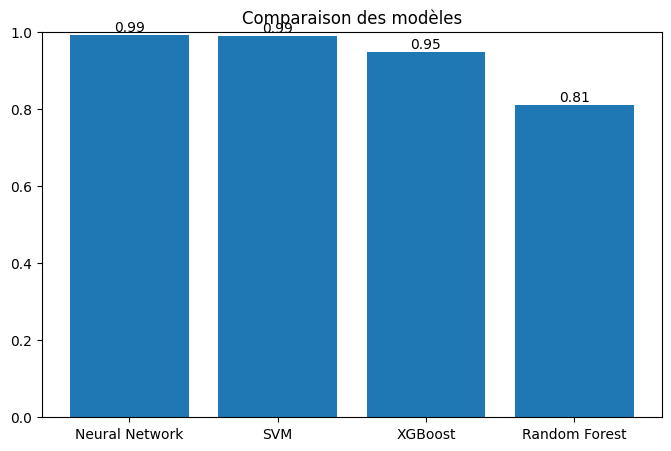

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.bar(df_results["Model"], df_results["Accuracy"])

for i, v in enumerate(df_results["Accuracy"]):
    plt.text(i, v + 0.01, f"{v:.2f}", ha='center')

plt.title("Comparaison des modèles")
plt.ylim(0,1)
plt.show()

MATRICE CONFUSION (XGBOOST FINAL)

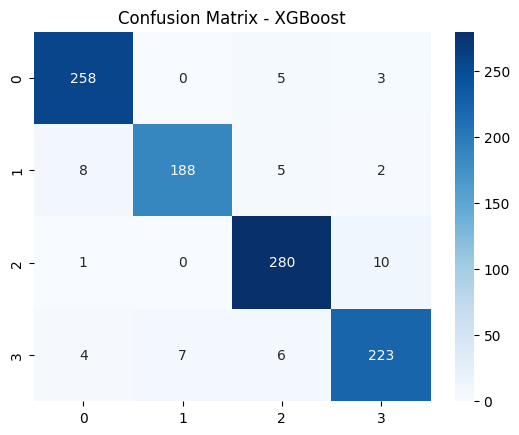

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

y_pred = best_xgb.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - XGBoost")
plt.show()

MODÈLE FINAL + PREDICTION

In [ ]:
# ===============================
# TEST PATIENT
# ===============================

sample = X_test.iloc[[3]]  # exemple
pred = best_xgb.predict(sample)

print("Classe prédite:", pred[0])
print("Trouble:", le.inverse_transform(pred)[0])

Classe prédite: 0
Trouble: Concentration


SAUVEGARDE DU MODÈLE (OBLIGATOIRE)

In [ ]:
import joblib

joblib.dump(best_xgb, "model_final.pkl")
joblib.dump(le, "label_encoder.pkl")

print("Modèle sauvegardé")

Modèle sauvegardé


TEST SUR NOUVEAU PATIENT

In [ ]:
# Exemple patient
new_patient = X_test.iloc[[0]]

prediction = best_xgb.predict(new_patient)

print("Classe prédite :", prediction[0])
print("Trouble :", le.inverse_transform(prediction)[0])

Classe prédite : 2
Trouble : Type_dysgraphie


In [ ]:
import pandas as pd

importance = best_xgb.feature_importances_
features = X.columns

df_imp = pd.DataFrame({
    "feature": features,
    "importance": importance
}).sort_values(by="importance", ascending=False)

print(df_imp.head(10))

                   feature  importance
21       boredom_tolerance    0.102729
19    attention_span_15min    0.093139
20    slow_task_completion    0.084254
12       writing_alignment    0.050095
4            avoid_reading    0.049674
13      copying_difficulty    0.049336
11    homework_misspelling    0.049239
10  number_writing_clarity    0.047836
14   math_symbol_confusion    0.046773
6         letter_confusion    0.046650


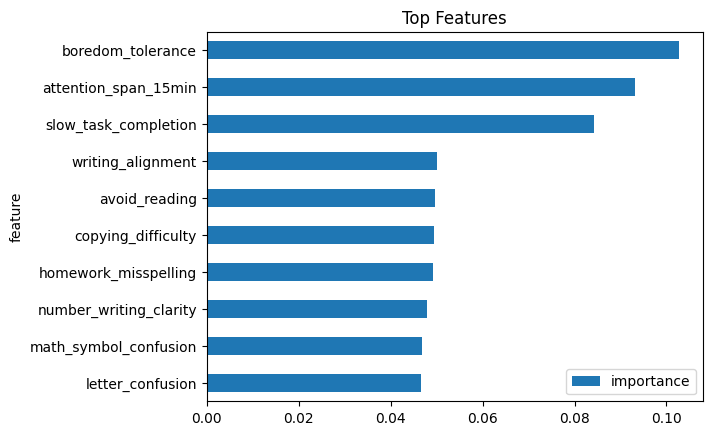

In [ ]:
import matplotlib.pyplot as plt

df_imp.head(10).plot(kind="barh", x="feature", y="importance")
plt.title("Top Features")
plt.gca().invert_yaxis()
plt.show()

Cas Dyslexie

In [ ]:
new_patient = pd.DataFrame([{
    'health_problems': 0,
    'social_family_problems': 0,
    'gap_results_potential': 1,
    'difficulty_area': 1,
    'avoid_reading': 2,
    'reading_speed': 0,
    'letter_confusion': 2,
    'reading_unknown_words': 2,
    'reading_comprehension': 2,
    'number_reversal': 0,
    'number_writing_clarity': 0,
    'homework_misspelling': 2,
    'writing_alignment': 1,
    'copying_difficulty': 1,
    'math_symbol_confusion': 0,
    'math_size_comparison': 0,
    'time_money_concepts': 0,
    'math_statement_understanding': 0,
    'calculation_difficulty': 0,
    'attention_span_15min': 1,
    'slow_task_completion': 1,
    'boredom_tolerance': 1
}])

In [ ]:
prediction = best_xgb.predict(new_patient)

print("Classe prédite :", prediction[0])
print("Trouble :", le.inverse_transform(prediction)[0])

Classe prédite : 3
Trouble : Type_dyslexie


Cas Dyscalculie

In [ ]:
new_patient = pd.DataFrame([{
    'health_problems': 0,
    'social_family_problems': 0,
    'gap_results_potential': 1,
    'difficulty_area': 1,
    'avoid_reading': 0,
    'reading_speed': 1,
    'letter_confusion': 0,
    'reading_unknown_words': 0,
    'reading_comprehension': 0,
    'number_reversal': 2,
    'number_writing_clarity': 2,
    'homework_misspelling': 1,
    'writing_alignment': 1,
    'copying_difficulty': 1,
    'math_symbol_confusion': 2,
    'math_size_comparison': 2,
    'time_money_concepts': 2,
    'math_statement_understanding': 2,
    'calculation_difficulty': 2,
    'attention_span_15min': 1,
    'slow_task_completion': 1,
    'boredom_tolerance': 1
}])

In [ ]:
prediction = best_xgb.predict(new_patient)

print("Classe prédite :", prediction[0])
print("Trouble :", le.inverse_transform(prediction)[0])

Classe prédite : 1
Trouble : Type_dyscalculie


Cas Concentration

In [ ]:
new_patient = pd.DataFrame([{
    'health_problems': 0,
    'social_family_problems': 1,
    'gap_results_potential': 1,
    'difficulty_area': 0,
    'avoid_reading': 0,
    'reading_speed': 1,
    'letter_confusion': 0,
    'reading_unknown_words': 0,
    'reading_comprehension': 1,
    'number_reversal': 0,
    'number_writing_clarity': 0,
    'homework_misspelling': 1,
    'writing_alignment': 1,
    'copying_difficulty': 1,
    'math_symbol_confusion': 0,
    'math_size_comparison': 0,
    'time_money_concepts': 1,
    'math_statement_understanding': 1,
    'calculation_difficulty': 1,
    'attention_span_15min': 2,
    'slow_task_completion': 2,
    'boredom_tolerance': 2
}])

In [ ]:
prediction = best_xgb.predict(new_patient)

print("Classe prédite :", prediction[0])
print("Trouble :", le.inverse_transform(prediction)[0])

Classe prédite : 0
Trouble : Concentration


XAI
Installation

In [ ]:
!pip install shap

In [ ]:
import shap

CRÉER L’EXPLAINER

In [ ]:
explainer = shap.Explainer(best_xgb)
shap_values = explainer(X_test)

VISUALISATION GLOBALE importance des variables impact positif ou négatif rouge = valeur élevée bleu = valeur faible droite = augmente la prédiction gauche = diminue

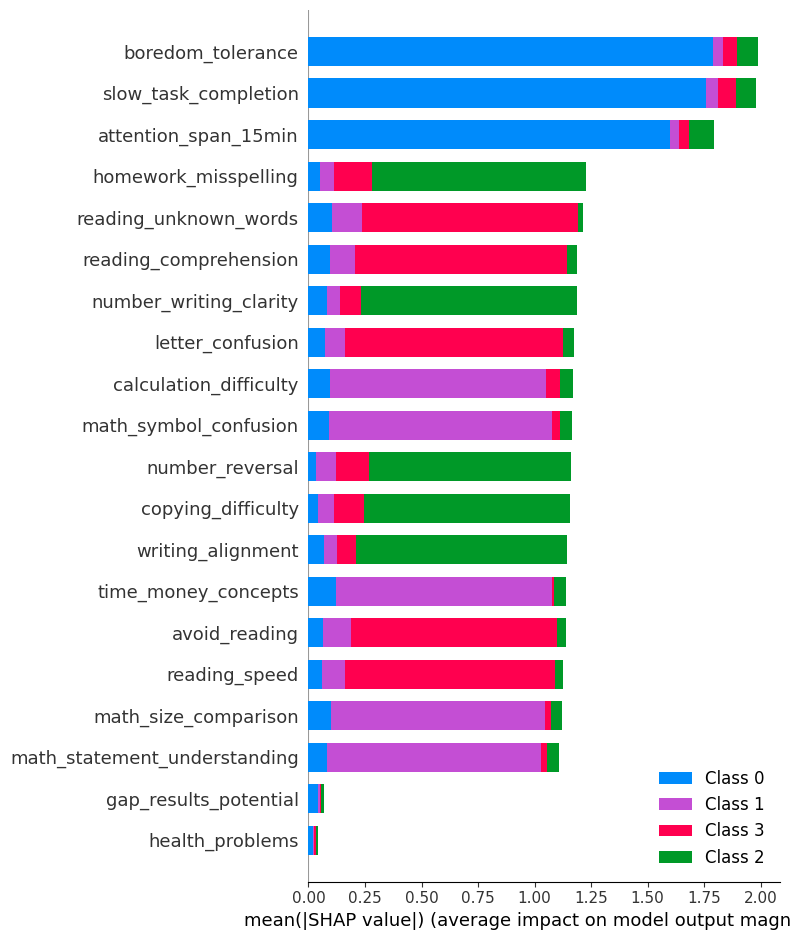

In [ ]:
shap.summary_plot(shap_values, X_test)

EXPLIQUER UN PATIENT

SHAP Waterfall Plot (figure)


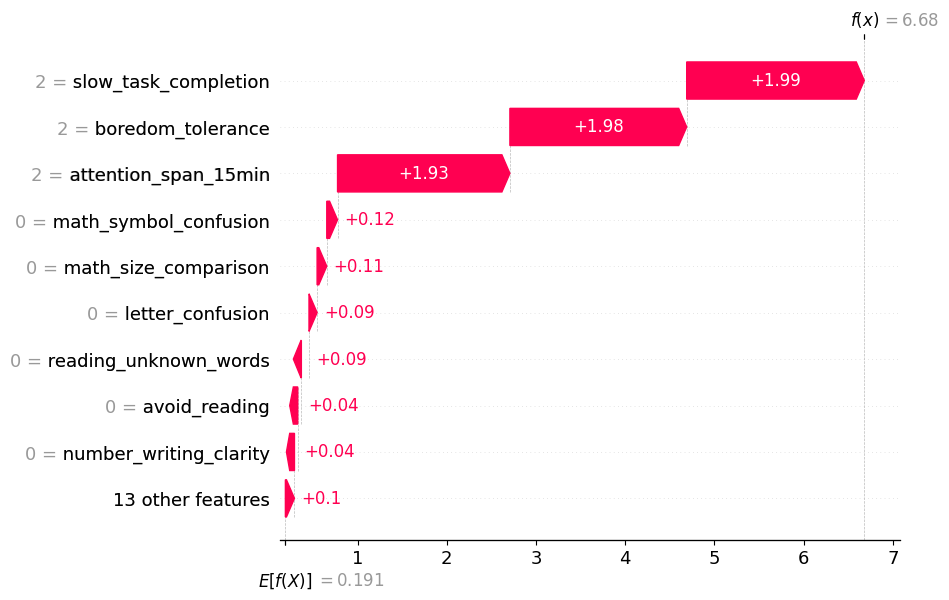

In [ ]:
pred_class = prediction[0]

shap_values_patient = explainer(new_patient)

shap.plots.waterfall(shap_values_patient[0, :, pred_class])

In [ ]:
shap_values_patient = explainer(new_patient)

pred_class = prediction[0]

shap.plots.waterfall(shap_values_patient[0, :, pred_class])

Global explantation

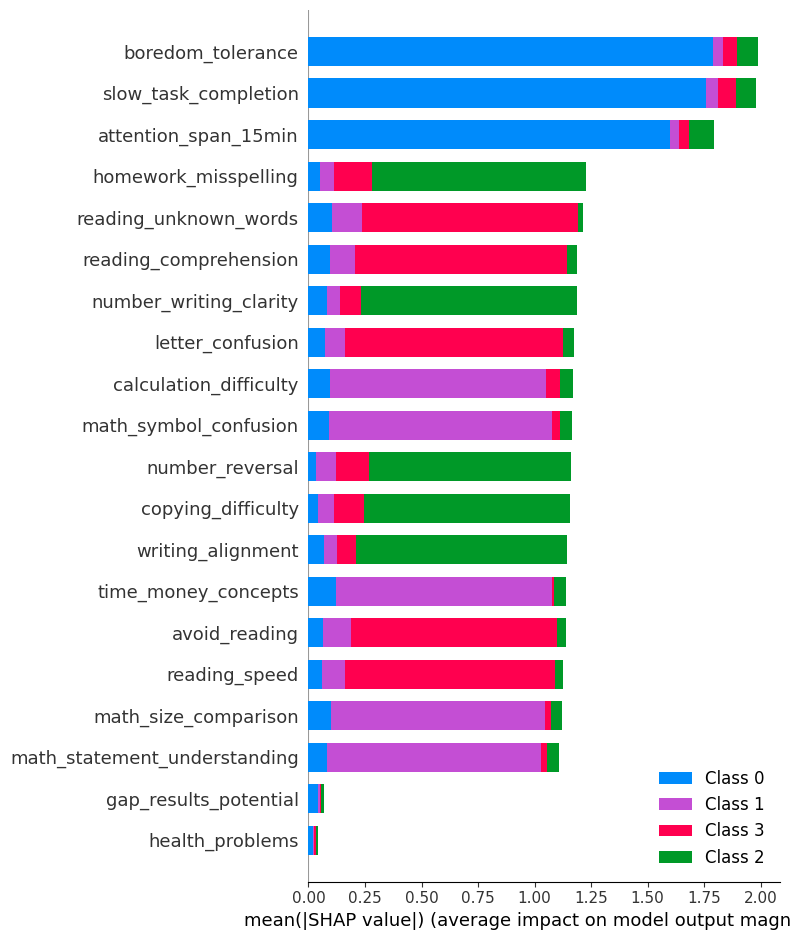

In [ ]:
shap.summary_plot(shap_values, X_test)

In [ ]:
from google.colab import files

files.download("model_final.pkl")
files.download("label_encoder.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>